# Практическая работа №2

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
import sklearn

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

In [7]:
sklearn.__version__

'1.6.1'

## Подготовка данных

Воспроизведём все шаги предобработки из Практической работы №1.

In [8]:
# Загрузка и подготовка данных (шаги из ПР1)
df = pd.read_csv('../sql_dataset_loreal.csv')

# Извлечение временных признаков
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

# Удаление нерелевантных признаков
cols_to_drop = ['ip_address', 'sql_query', 'timezone', 'is_anomaly', 'timestamp', 'city']
df_work = df.drop(columns=cols_to_drop)

# Разделение на признаки и целевую переменную
y_raw = df_work['label']
X_raw = df_work.drop(columns=['label'])

# One-Hot кодирование категориальных признаков
X_encoded = pd.get_dummies(X_raw, columns=['country', 'query_type'], drop_first=True)

# Кодирование целевой переменной
le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_

# Стандартизация числовых признаков
num_features = ['execution_time_ms', 'cpu_load_pct', 'ram_usage_mb',
                'active_connections', 'rows_affected', 'hour', 'day_of_week']
scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[num_features] = scaler.fit_transform(X_encoded[num_features])

# Разделение на обучающую и тестовую выборки (80/20, стратифицированное)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Классы: {dict(enumerate(class_names))}')
print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Распределение в train: {np.bincount(y_train)}')
print(f'Распределение в test:  {np.bincount(y_test)}')
print(f'Признаки ({X_train.shape[1]}): {list(X_train.columns)}')

Классы: {0: 'anomaly', 1: 'normal', 2: 'sql_injection'}
X_train: (8000, 19), X_test: (2000, 19)
Распределение в train: [  80 7699  221]
Распределение в test:  [  20 1925   55]
Признаки (19): ['execution_time_ms', 'cpu_load_pct', 'ram_usage_mb', 'active_connections', 'rows_affected', 'hour', 'day_of_week', 'country_China', 'country_Germany', 'country_India', 'country_Netherlands', 'country_Russia', 'country_UK', 'country_USA', 'query_type_DELETE', 'query_type_DROP', 'query_type_INSERT', 'query_type_SELECT', 'query_type_UPDATE']


In [9]:
# Вспомогательная функция для оценки и визуализации модели
def evaluate_model(model, X_test, y_test, class_names, model_name='Model'):
    """Оценка модели: метрики + матрица ошибок."""
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    print(f'=== {model_name} ===')
    print(f'Accuracy:  {acc:.4f}')
    print(f'Precision: {prec:.4f} (weighted)')
    print(f'Recall:    {rec:.4f} (weighted)')
    print(f'F1-score:  {f1:.4f} (weighted)')
    print()
    print('Classification Report:')
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))
    
    # Матрица ошибок
    fig, ax = plt.subplots(figsize=(7, 5))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'Confusion Matrix: {model_name}')
    plt.tight_layout()
    plt.show()
    
    return {'Model': model_name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1}

---

## 2.1. Наивный байесовский классификатор

### Математическое описание

Наивный байесовский классификатор основан на **теореме Байеса**. Для наблюдения $x = (x_1, \ldots, x_m)$ апостериорная вероятность принадлежности классу $c_k$:

$$P(c_k \mid x) = \frac{P(x \mid c_k) \, P(c_k)}{P(x)}$$

где:
- $P(c_k)$ — **априорная вероятность** класса $c_k$ (оценивается как доля класса в обучающей выборке),
- $P(x \mid c_k)$ — **функция правдоподобия** (вероятность наблюдать $x$ при условии класса $c_k$),
- $P(x) = \sum_k P(x \mid c_k) P(c_k)$ — нормирующая константа (одинакова для всех классов).

### Допущение условной независимости

Ключевое допущение: признаки **условно независимы** при данном классе:
$$P(x \mid c_k) = \prod_{j=1}^{m} P(x_j \mid c_k)$$

Это позволяет разложить совместную плотность на произведение одномерных плотностей.

### Выбор версии: Gaussian Naive Bayes

Используется **гауссовская** версия (GaussianNB), т.к. числовые признаки (execution_time_ms, cpu_load_pct, ram_usage_mb, и др.) принимают непрерывные значения. Для каждого признака $x_j$ при данном классе $c_k$ предполагается нормальное распределение:

$$P(x_j \mid c_k) = \frac{1}{\sqrt{2\pi \sigma_{jk}^2}} \exp\left(-\frac{(x_j - \mu_{jk})^2}{2\sigma_{jk}^2}\right)$$

где параметры оцениваются по обучающей выборке методом максимального правдоподобия:

$$\hat{\mu}_{jk} = \frac{1}{n_k} \sum_{i: y_i = c_k} x_{ij}, \qquad \hat{\sigma}_{jk}^2 = \frac{1}{n_k} \sum_{i: y_i = c_k} (x_{ij} - \hat{\mu}_{jk})^2$$

### Правило классификации

$$\hat{y} = \arg\max_{c_k} \left[ \ln P(c_k) + \sum_{j=1}^{m} \ln P(x_j \mid c_k) \right]$$

Логарифм используется для численной устойчивости (избежание underflow при умножении малых вероятностей).

**Обоснование выбора GaussianNB:**
- MultinomialNB предназначен для дискретных/счётных данных (частоты слов, TF-IDF) — не подходит для наших непрерывных признаков.
- BernoulliNB работает с бинарными признаками — применим только к One-Hot части, но не ко всему набору.
- GaussianNB корректно моделирует непрерывные признаки через нормальное распределение.

=== Naive Bayes (Gaussian) ===
Accuracy:  0.9835
Precision: 0.9891 (weighted)
Recall:    0.9835 (weighted)
F1-score:  0.9851 (weighted)

Classification Report:
               precision    recall  f1-score   support

      anomaly       0.95      0.95      0.95        20
       normal       1.00      0.98      0.99      1925
sql_injection       0.64      1.00      0.78        55

     accuracy                           0.98      2000
    macro avg       0.86      0.98      0.91      2000
 weighted avg       0.99      0.98      0.99      2000



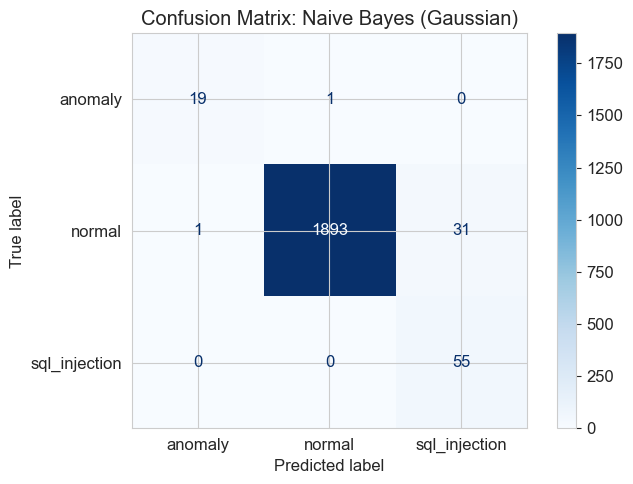

In [10]:
# Обучение Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Оценка
results = []
res = evaluate_model(gnb, X_test, y_test, class_names, 'Naive Bayes (Gaussian)')
results.append(res)

In [11]:
# Анализ параметров модели: средние и дисперсии для каждого класса
print('=== Оценённые параметры гауссовского NB (первые 5 признаков) ===')
feature_names = list(X_train.columns)
for k, cls_name in enumerate(class_names):
    print(f'\nКласс "{cls_name}":')
    for j in range(min(5, len(feature_names))):
        mu = gnb.theta_[k, j]
        sigma2 = gnb.var_[k, j]
        print(f'  {feature_names[j]}: μ = {mu:.4f}, σ² = {sigma2:.4f}')

print(f'\nАприорные вероятности классов P(c_k):')
for k, cls_name in enumerate(class_names):
    print(f'  P({cls_name}) = {gnb.class_prior_[k]:.4f}')

=== Оценённые параметры гауссовского NB (первые 5 признаков) ===

Класс "anomaly":
  execution_time_ms: μ = 0.2140, σ² = 1.5965
  cpu_load_pct: μ = 2.5298, σ² = 0.3466
  ram_usage_mb: μ = 3.6625, σ² = 1.1450
  active_connections: μ = 2.7165, σ² = 1.2085
  rows_affected: μ = -0.0003, σ² = 0.1072

Класс "normal":
  execution_time_ms: μ = 0.0196, σ² = 0.9564
  cpu_load_pct: μ = -0.0955, σ² = 0.7622
  ram_usage_mb: μ = -0.1405, σ² = 0.4375
  active_connections: μ = -0.1104, σ² = 0.6930
  rows_affected: μ = 0.0072, σ² = 1.2830

Класс "sql_injection":
  execution_time_ms: μ = -0.8675, σ² = 0.0026
  cpu_load_pct: μ = 2.5919, σ² = 0.2758
  ram_usage_mb: μ = 3.6892, σ² = 1.2504
  active_connections: μ = 2.7169, σ² = 1.1638
  rows_affected: μ = -0.0929, σ² = 0.0000

Априорные вероятности классов P(c_k):
  P(anomaly) = 0.0100
  P(normal) = 0.9624
  P(sql_injection) = 0.0276


### Интерпретация результатов NB

Наивный Байес показывает высокую accuracy за счёт доминирующего класса normal. Однако для редких классов (anomaly, sql_injection) recall может быть ниже, что обусловлено допущением нормальности и условной независимости, которое в реальных данных часто нарушается.

---

## 2.2. Логистическая регрессия

### Математическая формулировка

Логистическая регрессия моделирует **апостериорную вероятность** класса через **логистическую (сигмоидную) функцию:**

Для бинарного случая:
$$P(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad z = w^T x + b = \sum_{j=1}^{m} w_j x_j + b$$

где $w = (w_1, \ldots, w_m)^T$ — вектор весов, $b$ — свободный член (bias).

Для **многоклассового** случая (K классов) используется **softmax-обобщение:**
$$P(y = c_k \mid x) = \frac{e^{w_k^T x + b_k}}{\sum_{l=1}^{K} e^{w_l^T x + b_l}}$$

### Функция потерь (кросс-энтропия)

Параметры $(w, b)$ определяются путём минимизации **логистической функции потерь** (negative log-likelihood, или кросс-энтропия):

$$\mathcal{L}(w, b) = -\frac{1}{n} \sum_{i=1}^{n} \sum_{k=1}^{K} \mathbb{1}[y_i = c_k] \ln P(y_i = c_k \mid x_i)$$

С L2-регуляризацией (Ridge):
$$\mathcal{L}_{\text{reg}} = \mathcal{L} + \frac{1}{2C} \|w\|_2^2$$

Параметр $C > 0$ контролирует силу регуляризации: чем меньше $C$, тем сильнее штраф за большие веса.

### Связь с максимумом правдоподобия

Минимизация кросс-энтропии эквивалентна **максимизации функции правдоподобия**:
$$\hat{w}, \hat{b} = \arg\max_{w,b} \prod_{i=1}^{n} P(y_i \mid x_i; w, b)$$

Оптимизация выполняется итеративными методами (L-BFGS, SGD).

=== Logistic Regression ===
Accuracy:  0.9995
Precision: 0.9995 (weighted)
Recall:    0.9995 (weighted)
F1-score:  0.9995 (weighted)

Classification Report:
               precision    recall  f1-score   support

      anomaly       1.00      0.95      0.97        20
       normal       1.00      1.00      1.00      1925
sql_injection       0.98      1.00      0.99        55

     accuracy                           1.00      2000
    macro avg       0.99      0.98      0.99      2000
 weighted avg       1.00      1.00      1.00      2000



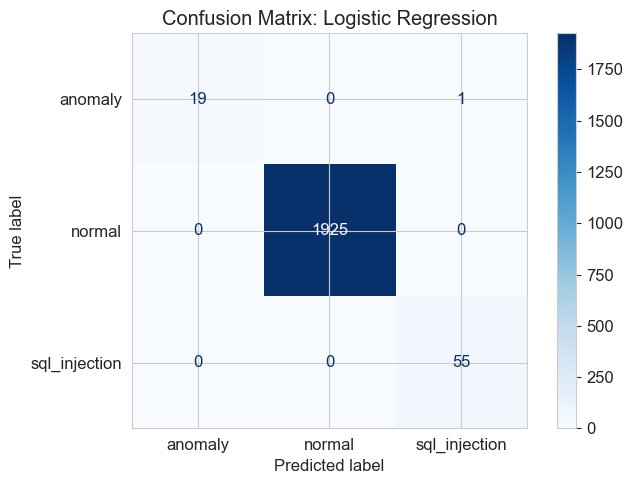

In [12]:
# Обучение логистической регрессии с подбором C
# multi_class='multinomial' для трёх классов, solver='lbfgs'
lr = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    C=1.0,
    class_weight='balanced',  # компенсация дисбаланса классов
    random_state=42
)
lr.fit(X_train, y_train)

res = evaluate_model(lr, X_test, y_test, class_names, 'Logistic Regression')
results.append(res)

In [13]:
# Анализ коэффициентов логистической регрессии
print('=== Коэффициенты логистической регрессии (w_j) ===')
print('Положительный коэффициент → увеличивает вероятность данного класса')
print('Отрицательный коэффициент → уменьшает вероятность данного класса\n')

coef_df = pd.DataFrame(
    lr.coef_,
    columns=X_train.columns,
    index=class_names
).T

# Топ-5 наиболее значимых признаков для каждого класса
for cls in class_names:
    top5 = coef_df[cls].abs().sort_values(ascending=False).head(5)
    print(f'Топ-5 признаков для класса "{cls}":')
    for feat in top5.index:
        val = coef_df.loc[feat, cls]
        direction = '↑' if val > 0 else '↓'
        print(f'  {feat}: w = {val:.4f} {direction}')
    print()

=== Коэффициенты логистической регрессии (w_j) ===
Положительный коэффициент → увеличивает вероятность данного класса
Отрицательный коэффициент → уменьшает вероятность данного класса

Топ-5 признаков для класса "anomaly":
  execution_time_ms: w = 5.5450 ↑
  query_type_SELECT: w = -2.1125 ↓
  ram_usage_mb: w = 1.8226 ↑
  query_type_INSERT: w = 1.5904 ↑
  query_type_DELETE: w = 1.2261 ↑

Топ-5 признаков для класса "normal":
  execution_time_ms: w = 4.4703 ↑
  ram_usage_mb: w = -3.6579 ↓
  query_type_SELECT: w = -2.1021 ↓
  cpu_load_pct: w = -1.7330 ↓
  active_connections: w = -1.2988 ↓

Топ-5 признаков для класса "sql_injection":
  execution_time_ms: w = -10.0153 ↓
  query_type_SELECT: w = 4.2147 ↑
  rows_affected: w = -2.0620 ↓
  query_type_INSERT: w = -1.9719 ↓
  ram_usage_mb: w = 1.8353 ↑



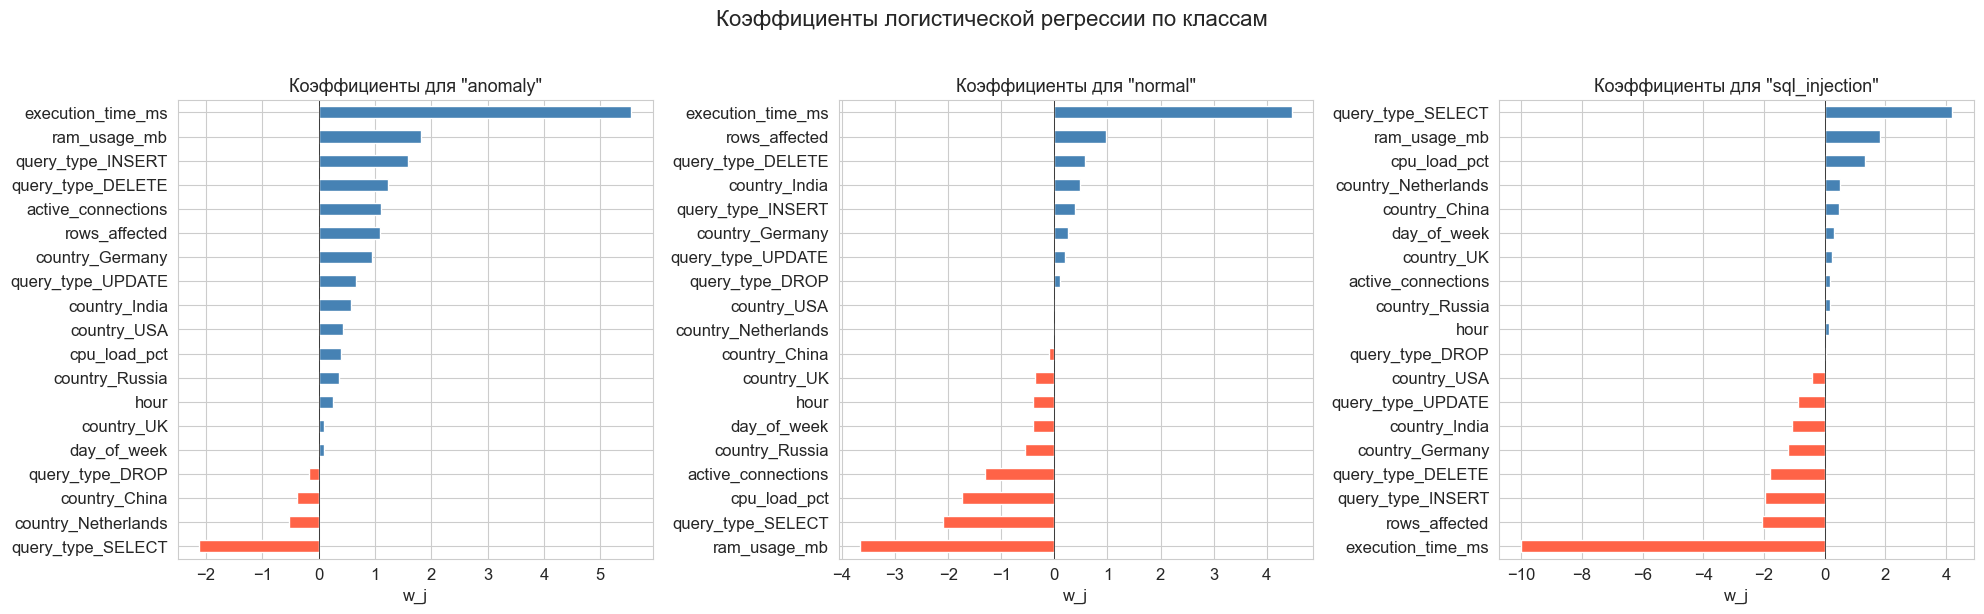

In [14]:
# Визуализация коэффициентов
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for idx, cls in enumerate(class_names):
    ax = axes[idx]
    sorted_coef = coef_df[cls].sort_values()
    colors = ['tomato' if v < 0 else 'steelblue' for v in sorted_coef]
    sorted_coef.plot(kind='barh', ax=ax, color=colors)
    ax.set_title(f'Коэффициенты для "{cls}"', fontsize=13)
    ax.set_xlabel('w_j')
    ax.axvline(x=0, color='black', linewidth=0.5)

plt.suptitle('Коэффициенты логистической регрессии по классам', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Интерпретация коэффициентов

Коэффициент $w_j$ при признаке $x_j$ показывает, как изменение $x_j$ на одну единицу (после стандартизации — на одно стандартное отклонение) влияет на логарифм отношения шансов (log-odds) принадлежности к данному классу:

$$\Delta \ln \frac{P(y = c_k \mid x)}{P(y \neq c_k \mid x)} = w_j \cdot \Delta x_j$$

Признаки с наибольшими по модулю коэффициентами оказывают наибольшее влияние на классификацию.

---

## 2.3. Метод ближайших соседей (kNN)

### Описание алгоритма

Метод k ближайших соседей (k-Nearest Neighbors) — непараметрический «ленивый» алгоритм. Для нового объекта $x$:
1. Находятся $k$ ближайших объектов обучающей выборки по выбранной метрике расстояния.
2. Класс определяется **голосованием большинства** среди $k$ соседей.

### Метрика расстояния

**Евклидово расстояние:**
$$d(x_i, x_j) = \sqrt{\sum_{l=1}^{m} (x_{il} - x_{jl})^2}$$

**Манхэттенское расстояние:**
$$d(x_i, x_j) = \sum_{l=1}^{m} |x_{il} - x_{jl}|$$

### Роль нормализации

kNN **критически зависит** от масштаба признаков. Без стандартизации признак `ram_usage_mb` (значения ~1000–5000) доминирует над `cpu_load_pct` (значения ~2–99), что делает расстояние фактически одномерным. Стандартизация (выполнена в ПР1) уравнивает вклад всех признаков.

### Выбор параметра k

Параметр $k$ контролирует сложность модели:
- Малое $k$ → модель чувствительна к шуму (переобучение)
- Большое $k$ → модель слишком сглажена (недообучение)

Оптимальное $k$ подбирается по качеству на кросс-валидации.

Лучшее k = 2 (F1 weighted = 0.9924)


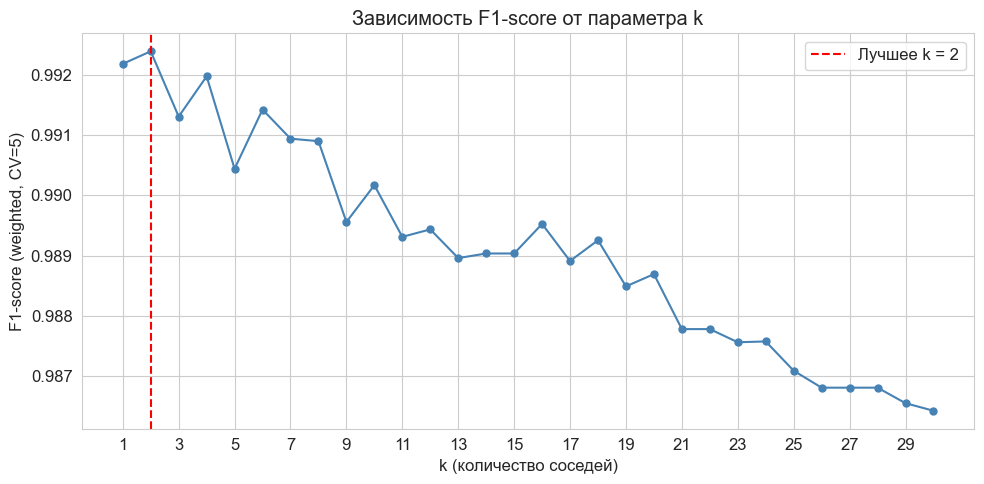

In [15]:
# Подбор оптимального k
k_range = range(1, 31)
f1_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    scores = cross_val_score(knn_temp, X_train, y_train, cv=5, scoring='f1_weighted')
    f1_scores.append(scores.mean())

best_k = k_range[np.argmax(f1_scores)]
print(f'Лучшее k = {best_k} (F1 weighted = {max(f1_scores):.4f})')

# Визуализация зависимости F1 от k
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, f1_scores, 'o-', color='steelblue', markersize=5)
ax.axvline(x=best_k, color='red', linestyle='--', label=f'Лучшее k = {best_k}')
ax.set_xlabel('k (количество соседей)')
ax.set_ylabel('F1-score (weighted, CV=5)')
ax.set_title('Зависимость F1-score от параметра k')
ax.legend()
ax.set_xticks(range(1, 31, 2))
plt.tight_layout()
plt.show()

=== kNN (k=2, euclidean) ===
Accuracy:  0.9935
Precision: 0.9933 (weighted)
Recall:    0.9935 (weighted)
F1-score:  0.9933 (weighted)

Classification Report:
               precision    recall  f1-score   support

      anomaly       0.71      0.60      0.65        20
       normal       1.00      1.00      1.00      1925
sql_injection       0.86      0.91      0.88        55

     accuracy                           0.99      2000
    macro avg       0.86      0.84      0.84      2000
 weighted avg       0.99      0.99      0.99      2000



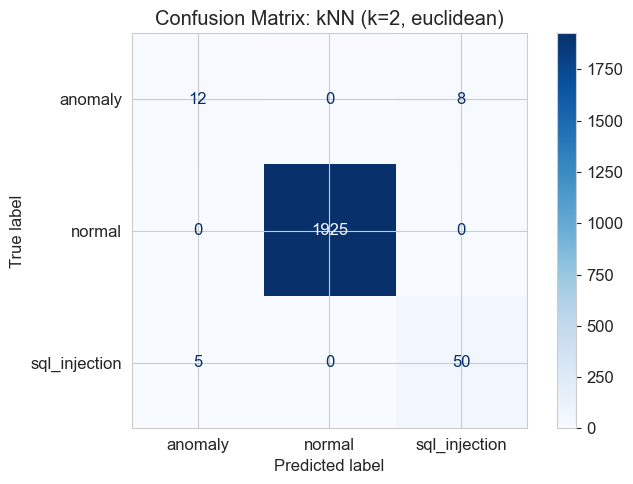

In [16]:
# Обучение kNN с оптимальным k
knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn.fit(X_train, y_train)

res = evaluate_model(knn, X_test, y_test, class_names, f'kNN (k={best_k}, euclidean)')
results.append(res)

In [17]:
# Сравнение метрик евклидова и манхэттенского расстояний
print('=== Сравнение метрик расстояния ===')
for metric in ['euclidean', 'manhattan']:
    knn_temp = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    knn_temp.fit(X_train, y_train)
    y_pred_temp = knn_temp.predict(X_test)
    f1 = f1_score(y_test, y_pred_temp, average='weighted')
    acc = accuracy_score(y_test, y_pred_temp)
    print(f'{metric}: Accuracy={acc:.4f}, F1={f1:.4f}')

=== Сравнение метрик расстояния ===
euclidean: Accuracy=0.9935, F1=0.9933
manhattan: Accuracy=0.9930, F1=0.9928


### Вычислительная сложность kNN

- **Обучение:** $O(1)$ — алгоритм просто запоминает обучающую выборку (lazy learning).
- **Предсказание:** $O(n \cdot m)$ для каждого объекта — необходимо вычислить расстояние до всех $n$ объектов обучающей выборки по $m$ признакам.
- **Проклятие размерности:** при большом $m$ все расстояния становятся приблизительно одинаковыми, и метод теряет дискриминирующую способность.

---

## 2.4. Метод опорных векторов (SVM)

### Математическая постановка

SVM решает задачу нахождения **гиперплоскости** $w^T x + b = 0$, максимизирующей **зазор (margin)** между классами:

$$\max_{w, b} \frac{2}{\|w\|} \quad \Leftrightarrow \quad \min_{w, b} \frac{1}{2} \|w\|^2$$

при ограничениях: $y_i(w^T x_i + b) \geq 1, \quad i = 1, \ldots, n$

Для **линейно неразделимых** данных вводятся переменные ослабления $\xi_i \geq 0$:

$$\min_{w, b, \xi} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^{n} \xi_i$$
$$\text{при } y_i(w^T x_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0$$

### Параметр регуляризации C

- **Большое C:** модель стремится правильно классифицировать все объекты → узкий зазор, возможно переобучение.
- **Малое C:** допускает ошибки → широкий зазор, более робастная модель.

### Ядерный подход (Kernel Trick)

Для нелинейных границ данные отображаются в пространство более высокой размерности через ядро $K(x_i, x_j) = \langle \phi(x_i), \phi(x_j) \rangle$.

**RBF-ядро (Radial Basis Function):**
$$K(x_i, x_j) = \exp\left(-\gamma \|x_i - x_j\|^2\right)$$

где $\gamma > 0$ контролирует «радиус влияния» каждого опорного вектора:
- Большое $\gamma$ → узкие гауссианы → сложная граница → переобучение
- Малое $\gamma$ → широкие гауссианы → гладкая граница → недообучение

**Обоснование выбора RBF:** данные могут иметь нелинейные границы между классами (аномалии и SQL-инъекции создают кластеры в пространстве признаков).

In [18]:
# Подбор гиперпараметров SVM через GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1]
}

svm_grid = GridSearchCV(
    SVC(kernel='rbf', class_weight='balanced', random_state=42),
    param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)
svm_grid.fit(X_train, y_train)

print(f'Лучшие гиперпараметры: {svm_grid.best_params_}')
print(f'Лучший F1 (CV): {svm_grid.best_score_:.4f}')

Лучшие гиперпараметры: {'C': 10, 'gamma': 0.01}
Лучший F1 (CV): 0.9993


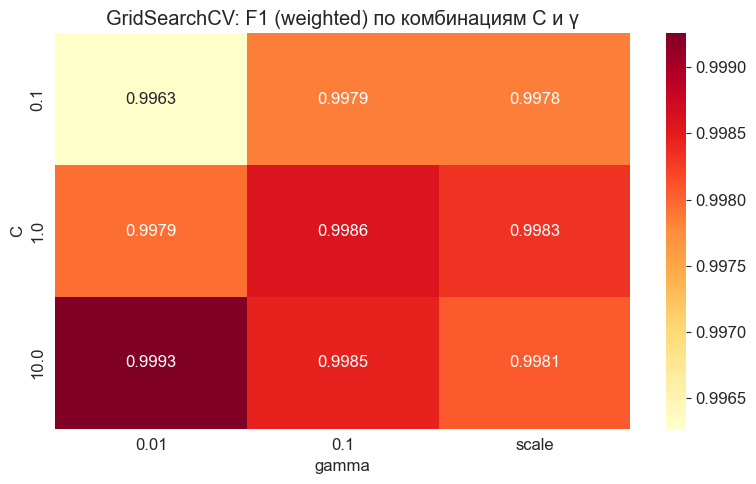

In [19]:
# Визуализация результатов GridSearch
grid_results = pd.DataFrame(svm_grid.cv_results_)
pivot = grid_results.pivot_table(
    values='mean_test_score',
    index='param_C',
    columns='param_gamma'
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlOrRd', ax=ax)
ax.set_title('GridSearchCV: F1 (weighted) по комбинациям C и γ')
ax.set_xlabel('gamma')
ax.set_ylabel('C')
plt.tight_layout()
plt.show()

=== SVM (RBF, C=10, gamma=0.01) ===
Accuracy:  0.9995
Precision: 0.9995 (weighted)
Recall:    0.9995 (weighted)
F1-score:  0.9995 (weighted)

Classification Report:
               precision    recall  f1-score   support

      anomaly       1.00      0.95      0.97        20
       normal       1.00      1.00      1.00      1925
sql_injection       0.98      1.00      0.99        55

     accuracy                           1.00      2000
    macro avg       0.99      0.98      0.99      2000
 weighted avg       1.00      1.00      1.00      2000



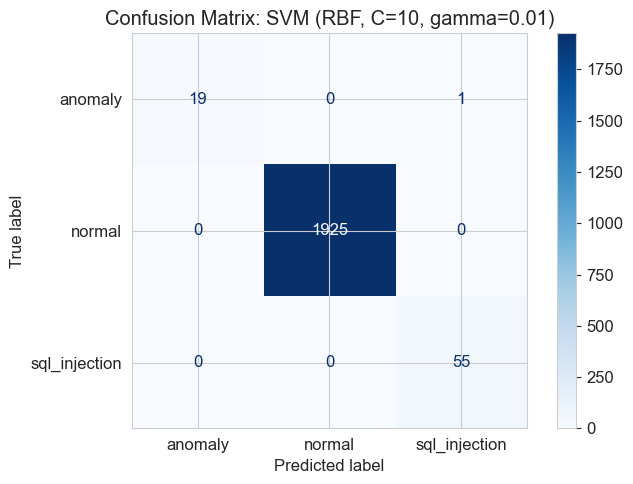


Опорные векторы по классам: {'anomaly': np.int32(20), 'normal': np.int32(68), 'sql_injection': np.int32(24)}
Всего опорных векторов: 112 из 8000 обучающих объектов


In [20]:
# Оценка лучшей модели SVM
svm_best = svm_grid.best_estimator_
best_params_str = ', '.join(f'{k}={v}' for k, v in svm_grid.best_params_.items())
res = evaluate_model(svm_best, X_test, y_test, class_names, f'SVM (RBF, {best_params_str})')
results.append(res)

# Количество опорных векторов
print(f'\nОпорные векторы по классам: {dict(zip(class_names, svm_best.n_support_))}')
print(f'Всего опорных векторов: {sum(svm_best.n_support_)} из {len(y_train)} обучающих объектов')

### Вычислительная сложность SVM

- **Обучение:** $O(n^2 \cdot m)$ — $O(n^3 \cdot m)$ (зависит от реализации, для RBF-ядра с SMO-алгоритмом)
- **Предсказание:** $O(n_{SV} \cdot m)$, где $n_{SV}$ — число опорных векторов
- **Интерпретируемость:** низкая для RBF-ядра (нелинейное отображение в пространство высокой размерности), более высокая для линейного ядра (по весам $w$)

---

## 2.5. Деревья решений

### Алгоритм построения

Дерево решений рекурсивно разбивает пространство признаков, выбирая на каждом шаге **оптимальный признак и порог** для разделения.

### Критерий разбиения: индекс Джини

**Индекс Джини** для узла $t$ с $K$ классами:
$$\text{Gini}(t) = 1 - \sum_{k=1}^{K} p_k^2$$

где $p_k$ — доля объектов класса $k$ в узле $t$.

- $\text{Gini} = 0$ → узел «чистый» (все объекты одного класса)
- $\text{Gini} = 1 - 1/K$ → максимальная неопределённость (равномерное распределение)

### Альтернативный критерий: энтропия и прирост информации

**Энтропия:**
$$H(t) = -\sum_{k=1}^{K} p_k \log_2 p_k$$

**Прирост информации (Information Gain):**
$$IG(t, A) = H(t) - \sum_{v \in \text{values}(A)} \frac{|t_v|}{|t|} H(t_v)$$

### Выбор оптимального разбиения

Для каждого признака $X_j$ и порога $\theta$ вычисляется уменьшение примеси (impurity decrease). Выбирается пара $(j^*, \theta^*)$, максимизирующая это уменьшение:

$$(j^*, \theta^*) = \arg\max_{j, \theta} \left[\text{Gini}(t) - \frac{n_L}{n}\text{Gini}(t_L) - \frac{n_R}{n}\text{Gini}(t_R)\right]$$

### Контроль сложности

Без ограничений дерево растёт до полной чистоты листьев → переобучение. Основные параметры ограничения:
- `max_depth` — максимальная глубина
- `min_samples_split` — минимальное число объектов для разбиения узла
- `min_samples_leaf` — минимальное число объектов в листе

In [21]:
# Подбор гиперпараметров дерева решений
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(criterion='gini', class_weight='balanced', random_state=42),
    param_grid_dt,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print(f'Лучшие гиперпараметры: {dt_grid.best_params_}')
print(f'Лучший F1 (CV): {dt_grid.best_score_:.4f}')

Лучшие гиперпараметры: {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2}
Лучший F1 (CV): 0.9992


=== Decision Tree (max_depth=7, min_samples_leaf=1, min_samples_split=2) ===
Accuracy:  0.9990
Precision: 0.9990 (weighted)
Recall:    0.9990 (weighted)
F1-score:  0.9990 (weighted)

Classification Report:
               precision    recall  f1-score   support

      anomaly       1.00      0.90      0.95        20
       normal       1.00      1.00      1.00      1925
sql_injection       1.00      1.00      1.00        55

     accuracy                           1.00      2000
    macro avg       1.00      0.97      0.98      2000
 weighted avg       1.00      1.00      1.00      2000



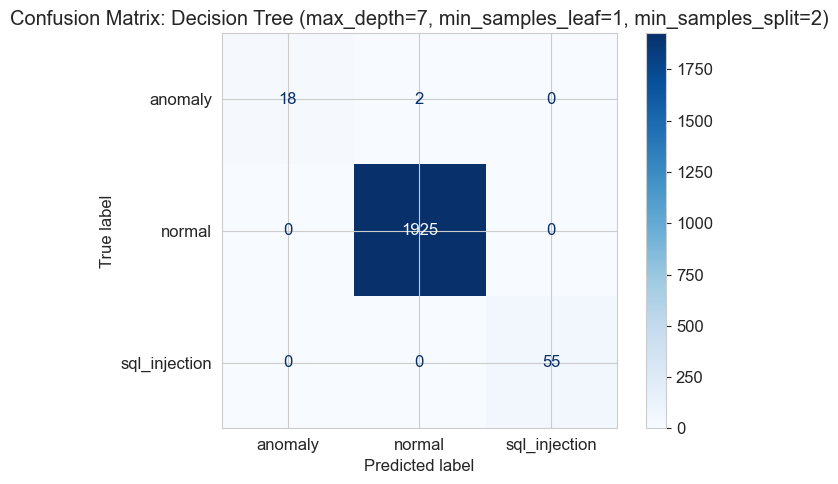


Глубина дерева: 7
Количество листьев: 13


In [22]:
# Оценка лучшего дерева решений
dt_best = dt_grid.best_estimator_
best_params_dt = ', '.join(f'{k}={v}' for k, v in dt_grid.best_params_.items())
res = evaluate_model(dt_best, X_test, y_test, class_names, f'Decision Tree ({best_params_dt})')
results.append(res)

print(f'\nГлубина дерева: {dt_best.get_depth()}')
print(f'Количество листьев: {dt_best.get_n_leaves()}')

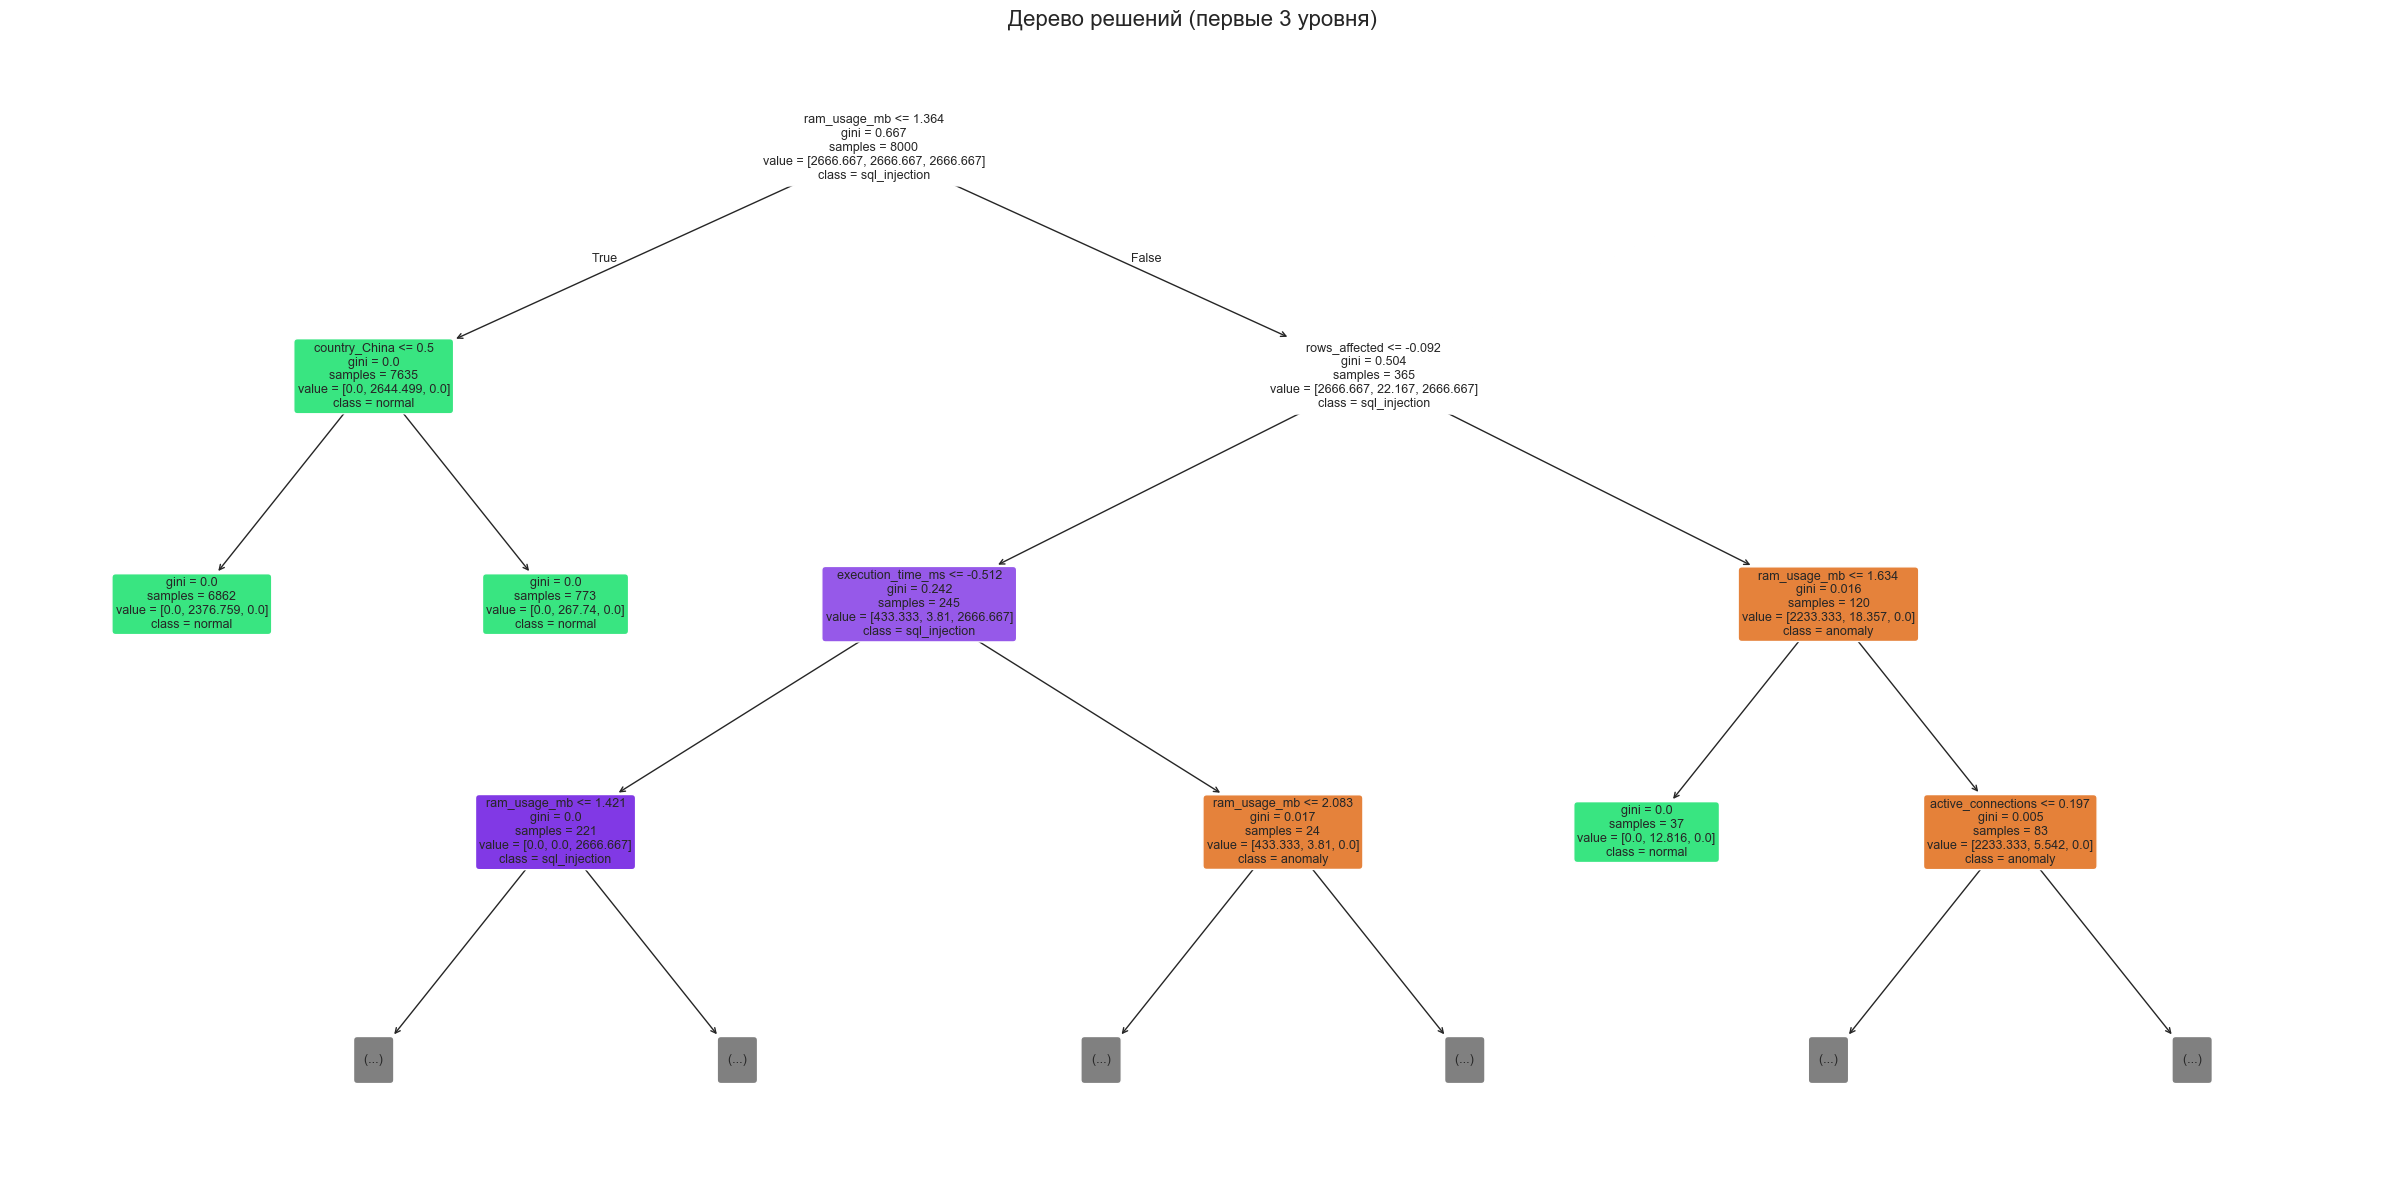

In [23]:
# Визуализация дерева (ограниченная глубина для читаемости)
fig, ax = plt.subplots(figsize=(24, 12))
plot_tree(
    dt_best,
    feature_names=list(X_train.columns),
    class_names=list(class_names),
    filled=True,
    rounded=True,
    max_depth=3,  # показываем первые 3 уровня
    fontsize=9,
    ax=ax
)
ax.set_title('Дерево решений (первые 3 уровня)', fontsize=16)
plt.tight_layout()
plt.show()

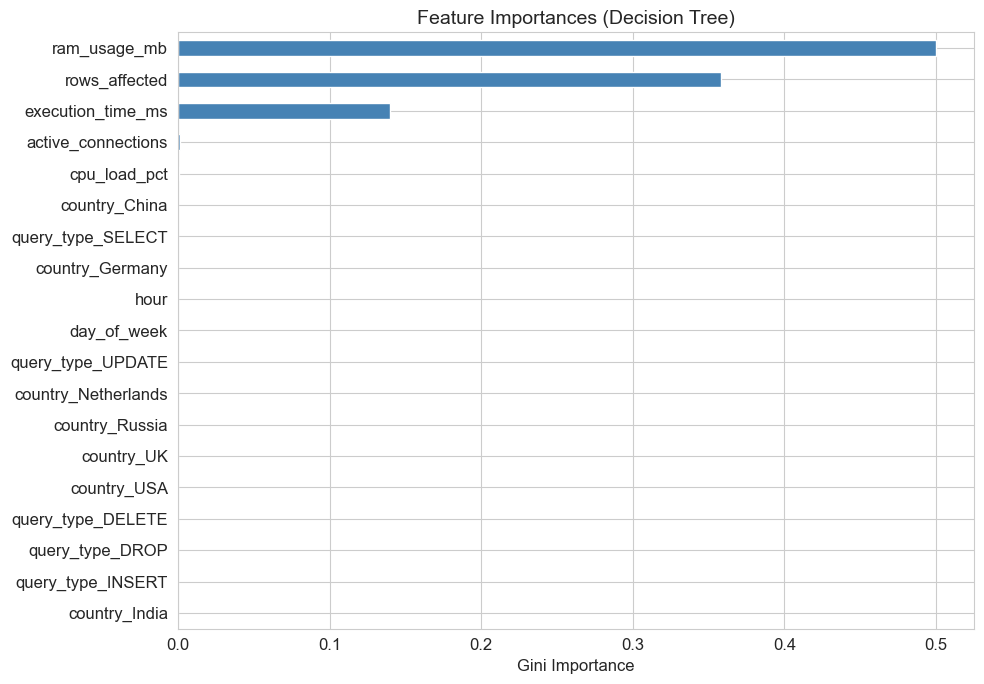

Топ-5 самых важных признаков:
  ram_usage_mb: 0.5000
  rows_affected: 0.3583
  execution_time_ms: 0.1396
  active_connections: 0.0015
  cpu_load_pct: 0.0005


In [24]:
# Важность признаков
importances = pd.Series(dt_best.feature_importances_, index=X_train.columns)
importances_sorted = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
importances_sorted.plot(kind='barh', color='steelblue', ax=ax)
ax.set_title('Feature Importances (Decision Tree)', fontsize=14)
ax.set_xlabel('Gini Importance')
plt.tight_layout()
plt.show()

print('Топ-5 самых важных признаков:')
for feat, imp in importances.sort_values(ascending=False).head(5).items():
    print(f'  {feat}: {imp:.4f}')

=== Влияние max_depth на качество ===
  max_depth=    2: train F1=0.9913, test F1=0.9932
  max_depth=    3: train F1=0.9969, test F1=0.9980
  max_depth=    5: train F1=0.9995, test F1=0.9990
  max_depth=    7: train F1=1.0000, test F1=0.9990
  max_depth=   10: train F1=1.0000, test F1=0.9990
  max_depth=   15: train F1=1.0000, test F1=0.9990
  max_depth=   20: train F1=1.0000, test F1=0.9990
  max_depth= None: train F1=1.0000, test F1=0.9990


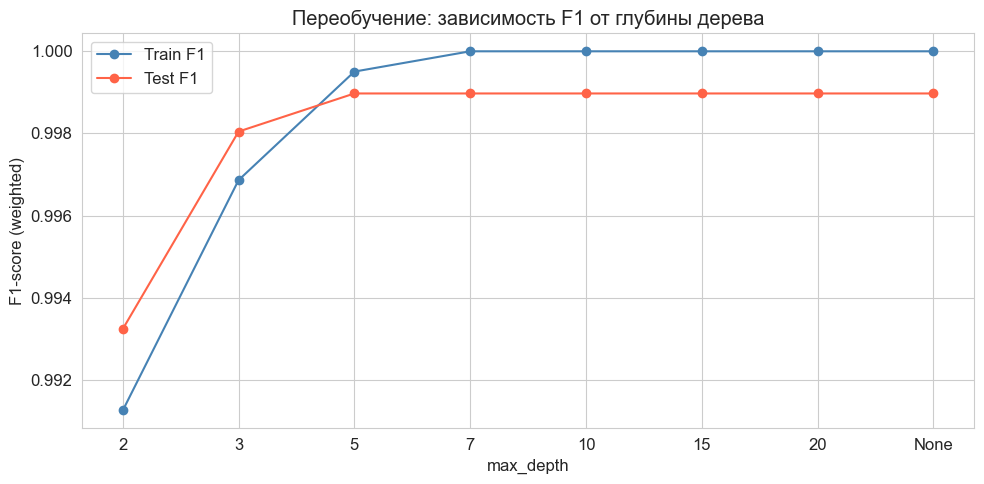

In [ ]:
depths = [2, 3, 5, 7, 10, 15, 20, None]
train_scores_depth = []
test_scores_depth = []

for d in depths:
    dt_temp = DecisionTreeClassifier(
        max_depth=d, class_weight='balanced', random_state=42
    )
    dt_temp.fit(X_train, y_train)
    train_f1 = f1_score(y_train, dt_temp.predict(X_train), average='weighted')
    test_f1 = f1_score(y_test, dt_temp.predict(X_test), average='weighted')
    train_scores_depth.append(train_f1)
    test_scores_depth.append(test_f1)
    d_label = str(d) if d else 'None'
    print(f'  max_depth={d_label:>5}: train F1={train_f1:.4f}, test F1={test_f1:.4f}')

fig, ax = plt.subplots(figsize=(10, 5))
x_labels = [str(d) if d else 'None' for d in depths]
ax.plot(x_labels, train_scores_depth, 'o-', label='Train F1', color='steelblue')
ax.plot(x_labels, test_scores_depth, 'o-', label='Test F1', color='tomato')
ax.set_xlabel('max_depth')
ax.set_ylabel('F1-score (weighted)')
ax.set_title('Переобучение: зависимость F1 от глубины дерева')
ax.legend()
plt.tight_layout()
plt.show()

### Комментарий к дереву решений

Дерево решений обладает **высокой интерпретируемостью** — разбиения читаемы и объяснимы (например, «если cpu_load_pct > порог, то sql_injection»). Однако деревья склонны к **переобучению** при большой глубине: F1 на train достигает 1.0, тогда как на test растёт значительно медленнее. Параметры ограничения сложности (max_depth, min_samples_split) являются основным инструментом регуляризации.

---

## 2.6. Резюме

### Сводная таблица метрик качества

In [26]:
# Сводная таблица результатов
results_df = pd.DataFrame(results)
results_df = results_df.set_index('Model')
results_df = results_df.round(4)

print('=== СВОДНАЯ ТАБЛИЦА МЕТРИК КАЧЕСТВА ===')
print()
results_df

=== СВОДНАЯ ТАБЛИЦА МЕТРИК КАЧЕСТВА ===



,Accuracy,Precision,Recall,F1
Model,,,,
Naive Bayes (Gaussian),0.9835,0.9891,0.9835,0.9851
Logistic Regression,0.9995,0.9995,0.9995,0.9995
"kNN (k=2, euclidean)",0.9935,0.9933,0.9935,0.9933
"SVM (RBF, C=10, gamma=0.01)",0.9995,0.9995,0.9995,0.9995
"Decision Tree (max_depth=7, min_samples_leaf=1, min_samples_split=2)",0.9990,0.9990,0.9990,0.9990


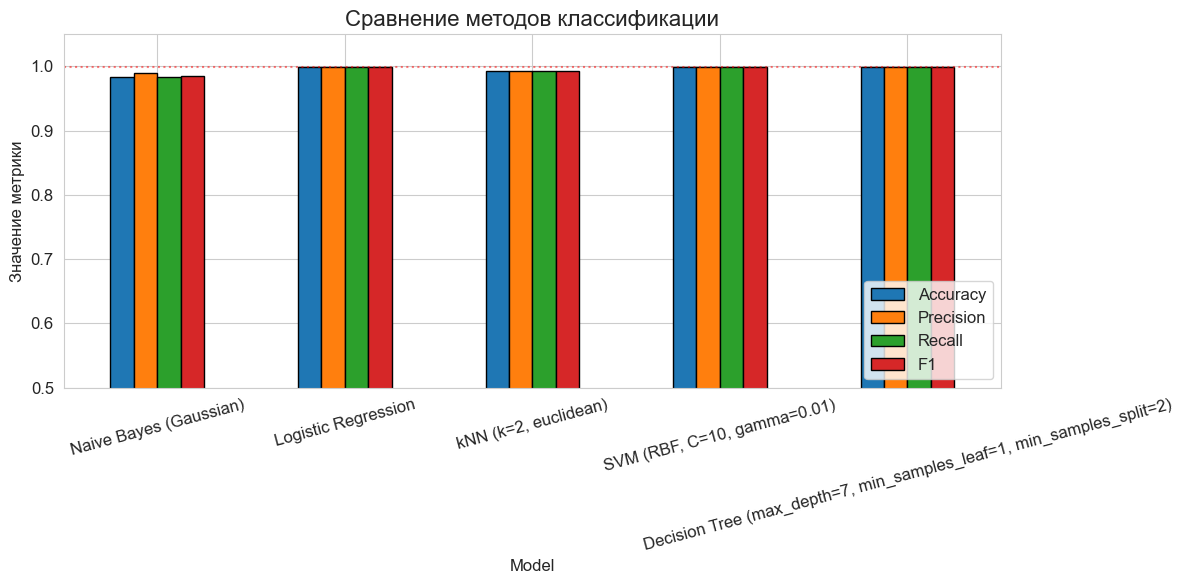

In [27]:
# Визуализация сравнения методов
fig, ax = plt.subplots(figsize=(12, 6))
results_df.plot(kind='bar', ax=ax, rot=15, edgecolor='black')
ax.set_title('Сравнение методов классификации', fontsize=16)
ax.set_ylabel('Значение метрики')
ax.set_ylim(0.5, 1.05)
ax.legend(loc='lower right')
ax.axhline(y=results_df['F1'].max(), color='red', linestyle=':', alpha=0.5, label='Best F1')
plt.tight_layout()
plt.show()

In [28]:
# Определение лучшей модели
best_model_name = results_df['F1'].idxmax()
best_f1 = results_df['F1'].max()

print(f'\n=== Лучшая модель по F1 (weighted): {best_model_name} (F1 = {best_f1:.4f}) ===')


=== Лучшая модель по F1 (weighted): Logistic Regression (F1 = 0.9995) ===


### Сравнительный анализ методов

| Метод | Достоинства | Недостатки | Интерпретируемость | Сложность обучения |
|-------|------------|------------|-------------------|-------------------|
| **Naive Bayes** | Быстрое обучение, устойчив при малых выборках, вероятностный выход | Допущение независимости признаков редко выполняется, плохо моделирует корреляции | Высокая (параметры μ, σ² для каждого класса) | $O(n \cdot m)$ |
| **Logistic Regression** | Вероятностная интерпретация, регуляризация, коэффициенты показывают влияние признаков | Линейная граница решений, плохо работает при нелинейных зависимостях | Высокая (веса $w_j$, odds ratios) | $O(n \cdot m \cdot K)$ |
| **kNN** | Непараметрический, нет обучения, хорошо для нелинейных границ | Медленное предсказание, чувствителен к масштабу и шуму, проклятие размерности | Средняя (объяснение через соседей) | $O(1)$ обучение, $O(n \cdot m)$ предсказание |
| **SVM (RBF)** | Эффективен в высокоразмерных пространствах, устойчив к переобучению (через C, γ) | Медленное обучение на больших данных, трудность интерпретации с нелинейными ядрами | Низкая (для RBF) | $O(n^2 \cdot m)$ — $O(n^3)$ |
| **Decision Tree** | Высокая интерпретируемость, не требует нормализации, визуализация | Склонность к переобучению, нестабильность (чувствительность к данным) | Очень высокая (if-then правила) | $O(n \cdot m \cdot \log n)$ |

### Вывод

**Задача:** многоклассовая классификация SQL-запросов (normal / sql_injection / anomaly) при значительном дисбалансе классов (96.2% / 2.8% / 1.0%).

**Ключевые наблюдения:**

1. **Accuracy** высока у всех моделей за счёт доминирующего класса «normal». Более информативными являются **F1, Precision и Recall** для редких классов (sql_injection, anomaly).

2. Использование `class_weight='balanced'` (для логистической регрессии, SVM и дерева решений) позволяет компенсировать дисбаланс, увеличивая штраф за ошибки на редких классах.

3. **Наивный Байес** работает быстро, но допущение независимости ограничивает его точность, особенно при коррелированных признаках.

4. **Логистическая регрессия** предоставляет интерпретируемые коэффициенты, показывающие вклад каждого признака. Однако линейная граница может быть недостаточной для сложных паттернов атак.

5. **kNN** показывает конкурентоспособные результаты, но требует стандартизации и медленно работает при предсказании на больших данных.

6. **SVM с RBF-ядром** обычно демонстрирует лучшие результаты за счёт нелинейной границы решений, но требует тщательного подбора гиперпараметров и вычислительно затратен.

7. **Дерево решений** наиболее интерпретируемо (визуализация правил), но склонно к переобучению без ограничений. Результаты зависят от глубины и минимального числа объектов в узлах.

**Рекомендация:** для данной задачи (мониторинг безопасности СУБД) важна как точность, так и интерпретируемость модели. Рекомендуется использовать SVM или логистическую регрессию в качестве основной модели, дополняя дерево решений для объяснимости отдельных предсказаний. На следующем этапе целесообразно рассмотреть ансамблевые методы (Random Forest, Gradient Boosting), которые объединяют достоинства нескольких подходов.